In [60]:

import os
from getpass import getpass

key = getpass("Paste your new LangSmith API key: ")

os.environ["LANGSMITH_API_KEY"] = key
os.environ["LANGCHAIN_API_KEY"] = key
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGSMITH_PROJECT"] = "Week 4 RAG Project"

print("LangSmith key configured for this Colab session.")

Paste your new LangSmith API key: ··········
LangSmith key configured for this Colab session.


In [61]:
import os

print("API key loaded:", bool(os.getenv("LANGSMITH_API_KEY")))
print("Tracing enabled:", os.getenv("LANGSMITH_TRACING"))
print("Project:", os.getenv("LANGSMITH_PROJECT"))

API key loaded: True
Tracing enabled: true
Project: Week 4 RAG Project


In [62]:
%pip install -q --upgrade langchain-core langchain-community langchain-google-genai langchain-text-splitters langgraph pypdf langsmith

In [63]:

from langchain_core.documents import Document

financial_report = """
ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.

Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.

Outlook:
Management expects to expand renewable energy capacity,
but future performance depends on execution, financing,
and market conditions.
"""

documents = [
    Document(
        page_content=financial_report,
        metadata={"source": "sample_financial_report"}
    )
]

print("Sample document loaded successfully.")
print("Number of documents:", len(documents))
print("Characters:", len(documents[0].page_content))

Sample document loaded successfully.
Number of documents: 1
Characters: 756


In [64]:

from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=350,
    chunk_overlap=50
)

chunks = text_splitter.split_documents(documents)

print("Number of chunks:", len(chunks))
print("\nFirst chunk:\n")
print(chunks[0].page_content)

Number of chunks: 3

First chunk:

ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.


In [65]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Extract the text from each chunk
chunk_texts = [chunk.page_content for chunk in chunks]

# Convert text into numerical representations
vectorizer = TfidfVectorizer(stop_words="english")
chunk_vectors = vectorizer.fit_transform(chunk_texts)

print("Retrieval system created successfully!")
print("Chunks indexed:", len(chunk_texts))

Retrieval system created successfully!
Chunks indexed: 3


In [66]:
def retrieve_context(question, top_k=2):
    # Convert the question into the same numerical representation
    question_vector = vectorizer.transform([question])

    # Find similarity between the question and each chunk
    similarities = cosine_similarity(
        question_vector, chunk_vectors
    ).flatten()

    # Select the most relevant chunks
    best_indices = similarities.argsort()[::-1][:top_k]

    results = []
    for index in best_indices:
        results.append({
            "score": round(float(similarities[index]), 3),
            "text": chunk_texts[index]
        })

    return results


# Test with a question about the sample report
question = "What was the company's revenue in FY 2025-26?"

results = retrieve_context(question)

for number, result in enumerate(results, start=1):
    print(f"\nResult {number} | Similarity: {result['score']}")
    print(result["text"])


Result 1 | Similarity: 0.556
ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.

Result 2 | Similarity: 0.391
Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.


In [67]:
# CELL 4: Create embeddings and vector database

# Install missing dependencies for HuggingFace embeddings and FAISS
%pip install -q langchain-huggingface faiss-cpu

from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

# Convert text chunks into embeddings
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

# Store the embeddings in a searchable database
vector_store = FAISS.from_documents(
    documents=chunks,
    embedding=embeddings
)

print("Success! Embeddings created and stored in FAISS.")
print("Total chunks stored:", len(chunks))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Success! Embeddings created and stored in FAISS.
Total chunks stored: 3


In [68]:

# CELL 5: Test document retrieval

question = "What does the report say about revenue?"

retriever = vector_store.as_retriever(
    search_kwargs={"k": 2}
)

results = retriever.invoke(question)

print("Question:", question)
print("\nRetrieved information:\n")

for i, doc in enumerate(results, start=1):
    print(f"Result {i}:")
    print(doc.page_content)
    print("-" * 40)

Question: What does the report say about revenue?

Retrieved information:

Result 1:
Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.
----------------------------------------
Result 2:
ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.
----------------------------------------


In [69]:

!pip install -q transformers sentencepiece

In [70]:
from transformers import pipeline

generator = pipeline(
    "text-generation",
    model="google/flan-t5-small"
)

print("Language model loaded successfully!")

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
[transformers] The model 'T5ForConditionalGeneration' is not supported for text-generation. Supported models are ['PeftModelForCausalLM', 'AfmoeForCausalLM', 'ApertusForCausalLM', 'ArceeForCausalLM', 'AriaTextForCausalLM', 'AXK1ForCausalLM', 'AXK2ForCausalLM', 'BambaForCausalLM', 'BartForCausalLM', 'BertLMHeadModel', 'BertGenerationDecoder', 'BigBirdForCausalLM', 'BigBirdPegasusForCausalLM', 'BioGptForCausalLM', 'BitNetForCausalLM', 'BlenderbotForCausalLM', 'BlenderbotSmallForCausalLM', 'BloomForCausalLM', 'BltForCausalLM', 'CamembertForCausalLM', 'CodeGenForCausalLM', 'CohereForCausalLM', 'Cohere2ForCausalLM', 'Cohere2MoeForCausalLM', 'CohereCompassForCausalLM', 'CpmAntForCausalLM', 'CTRLLMHeadModel

Language model loaded successfully!


In [71]:

def ask_rag(question):
    # Retrieve relevant passages
    results = retriever.invoke(question)

    # Combine the passages into context
    context = "\n\n".join(
        doc.page_content for doc in results
    )

    # Ask the model to answer using the context
    prompt = f"""
    Answer the question using only the context below.
    If the answer is not available, say:
    "The document does not provide enough information."

    Context:
    {context}

    Question: {question}

    Answer:
    """

    output = generator(
        prompt,
        max_new_tokens=150,
        do_sample=False
    )

    return output[0]["generated_text"]


question = "What does the report say about revenue?"
print("Answer:", ask_rag(question))

[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Answer: 
    Answer the question using only the context below.
    If the answer is not available, say:
    "The document does not provide enough information."

    Context:
    Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.

ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.

    Question: What does the report say about revenue?

    Answer:
    


In [72]:

test = generator(
    "Answer this question: What is 2 plus 2?",
    max_new_tokens=30,
    do_sample=False,
    return_full_text=False
)

print(repr(test[0]["generated_text"]))

[transformers] Both `max_new_tokens` (=30) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


''


In [73]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, pipeline

model_name = "google/flan-t5-small"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

generator = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer
)

test = generator(
    "What is 2 plus 2? Answer briefly.",
    max_new_tokens=30,
    do_sample=False
)

print("Model response:", repr(test[0]["generated_text"]))

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
[transformers] The model 'T5ForConditionalGeneration' is not supported for text-generation. Supported models are ['PeftModelForCausalLM', 'AfmoeForCausalLM', 'ApertusForCausalLM', 'ArceeForCausalLM', 'AriaTextForCausalLM', 'AXK1ForCausalLM', 'AXK2ForCausalLM', 'BambaForCausalLM', 'BartForCausalLM', 'BertLMHeadModel', 'BertGenerationDecoder', 'BigBirdForCausalLM', 'BigBirdPegasusForCausalLM', 'BioGptForCausalLM', 'BitNetForCausalLM', 'BlenderbotForCausalLM', 'BlenderbotSmallForCausalLM', 'BloomForCausalLM', 'BltForCausalLM', 'CamembertForCausalLM', 'CodeGenForCausalLM', 'CohereForCausalLM', 'Cohere2ForCausalLM', 'Cohere2MoeForCausalLM', 'CohereCompassForCausalLM', 'CpmAntForCausalLM', 'CTRLLMHeadModel

Model response: 'What is 2 plus 2? Answer briefly.'


In [74]:
def ask_rag(question):
    results = retriever.invoke(question)

    context = "\n\n".join(
        doc.page_content for doc in results
    )

    prompt = (
        "Answer the question using the context. "
        "If the answer is missing, say insufficient information.\n\n"
        f"Context: {context}\n\n"
        f"Question: {question}\n"
        "Answer:"
    )

    # Use return_full_text=False to prevent returning the prompt text
    output = generator(
        prompt,
        max_new_tokens=100,
        do_sample=False,
        return_full_text=False
    )

    return output[0]["generated_text"].strip()


print(ask_rag("What was the company's revenue in FY 2025-26?"))

[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


In [75]:

def ask_rag(question):
    results = retriever.invoke(question)

    context = "\n\n".join(
        doc.page_content for doc in results
    )

    prompt = (
        "Answer the question using the context. "
        "If the answer is missing, say insufficient information.\n\n"
        f"Context: {context}\n\n"
        f"Question: {question}\n"
        "Answer:"
    )

    output = generator(
        prompt,
        max_new_tokens=100,
        do_sample=False
    )

    return output[0]["generated_text"].strip()


print(ask_rag("What was the company's revenue in FY 2025-26?"))

[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Answer the question using the context. If the answer is missing, say insufficient information.

Context: Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.

ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.

Question: What was the company's revenue in FY 2025-26?
Answer:


In [76]:

# WEEK 4 - RAG EVALUATION

test_questions = [
    "What was the company's revenue in FY 2025-26?",
    "What was the company's revenue in FY 2024-25?",
    "What were the operating expenses in FY 2025-26?",
    "What was the operating profit in FY 2025-26?",
    "What was the total debt at the end of FY 2025-26?",
    "What business risks did the company identify?",
    "How many employees does the company have?"
]

for question in test_questions:
    print("\nQuestion:", question)

    answer = ask_rag(question)

    print("Answer:", answer)
    print("-" * 60)

[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Question: What was the company's revenue in FY 2025-26?


[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Answer: Answer the question using the context. If the answer is missing, say insufficient information.

Context: Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.

ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.

Question: What was the company's revenue in FY 2025-26?
Answer:
------------------------------------------------------------

Question: What was the company's revenue in FY 2024-25?


[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Answer: Answer the question using the context. If the answer is missing, say insufficient information.

Context: Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.

ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.

Question: What was the total debt at the end of FY 2025-26?
Answer:
------------------------------------------------------------

Question: What business risks did the company identify?


[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Answer: Answer the question using the context. If the answer is missing, say insufficient information.

Context: Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.

Outlook:
Management expects to expand renewable energy capacity,
but future performance depends on execution, financing,
and market conditions.

Question: What business risks did the company identify?
Answer:
------------------------------------------------------------

Question: How many employees does the company have?


[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Answer: Answer the question using the context. If the answer is missing, say insufficient information.

Context: Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.

ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.

Question: How many employees does the company have?
Answer:
------------------------------------------------------------


In [77]:

# WEEK 4 - SOURCE INSPECTION

question = "What was the company's revenue in FY 2025-26?"

retrieved_docs = retriever.invoke(question)

print("Question:", question)
print("\nRetrieved source passages:\n")

for i, doc in enumerate(retrieved_docs, start=1):
    print(f"Source {i}:")
    print(doc.page_content)
    print("-" * 50)

Question: What was the company's revenue in FY 2025-26?

Retrieved source passages:

Source 1:
Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.
--------------------------------------------------
Source 2:
ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.
--------------------------------------------------


In [78]:

%pip install -q langgraph

In [79]:

from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class RAGState(TypedDict):
    question: str
    context: str
    answer: str
    sources: list[str]

print("LangGraph state created successfully!")

LangGraph state created successfully!


In [80]:

def retrieve_node(state: RAGState):
    question = state["question"]

    docs = retriever.invoke(question)

    context = "\n\n".join(
        doc.page_content for doc in docs
    )

    sources = [
        doc.page_content for doc in docs
    ]

    return {
        "context": context,
        "sources": sources
    }

print("Retrieval node created!")

Retrieval node created!


In [81]:

def generate_node(state: RAGState):
    prompt = f"""
Answer the question using only the context below.
If the answer is not available, say:
The document does not provide enough information.

Context:
{state["context"]}

Question: {state["question"]}

Answer:
"""

    result = generator(
        prompt,
        max_new_tokens=100,
        do_sample=False
    )

    answer = result[0]["generated_text"].strip()

    return {"answer": answer}

print("Answer-generation node created!")

Answer-generation node created!


In [82]:

workflow = StateGraph(RAGState)

# Register the nodes
workflow.add_node("retrieve", retrieve_node)
workflow.add_node("generate", generate_node)

# Connect the workflow
workflow.add_edge(START, "retrieve")
workflow.add_edge("retrieve", "generate")
workflow.add_edge("generate", END)

# Compile the graph
rag_graph = workflow.compile()

print("LangGraph workflow compiled successfully!")

LangGraph workflow compiled successfully!


In [83]:

result = rag_graph.invoke({
    "question": "What was the company's revenue in FY 2025-26?",
    "context": "",
    "answer": "",
    "sources": []
})

print("QUESTION:")
print(result["question"])

print("\nGENERATED ANSWER:")
print(result["answer"])

print("\nRETRIEVED SOURCES:")
for source in result["sources"]:
    print("-", source)

[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


QUESTION:
What was the company's revenue in FY 2025-26?

GENERATED ANSWER:
Answer the question using only the context below.
If the answer is not available, say:
The document does not provide enough information.

Context:
Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.

ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.

Question: What was the company's revenue in FY 2025-26?

Answer:

RETRIEVED SOURCES:
- Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The co

In [84]:

print(rag_graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	retrieve(retrieve)
	generate(generate)
	__end__([<p>__end__</p>]):::last
	__start__ --> retrieve;
	retrieve --> generate;
	generate --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [85]:

%pip install -q langsmith

In [87]:

result = rag_graph.invoke({
    "question": "What was the company's revenue in FY 2025-26?",
    "context": "",
    "answer": "",
    "sources": []
})

print("Question:", result["question"])
print("Answer:", result["answer"])
print("Number of source passages:", len(result["sources"]))

[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Question: What was the company's revenue in FY 2025-26?
Answer: Answer the question using only the context below.
If the answer is not available, say:
The document does not provide enough information.

Context:
Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.

ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.

Question: What was the company's revenue in FY 2025-26?

Answer:
Number of source passages: 2


In [88]:

import os

print("Tracing enabled:", os.environ.get("LANGSMITH_TRACING"))
print("Project:", os.environ.get("LANGSMITH_PROJECT"))
print("API key present:", bool(os.environ.get("LANGSMITH_API_KEY")))

Tracing enabled: true
Project: Week 4 RAG Project
API key present: True


In [89]:

from langsmith import traceable
from langsmith import Client

client = Client()

@traceable(name="colab_connection_test")
def tracing_test():
    return {"status": "LangSmith tracing works!"}

print(tracing_test())

{'status': 'LangSmith tracing works!'}


In [90]:

from langsmith import Client

client = Client()

try:
    projects = list(client.list_projects(limit=5))
    print("Connection successful!")
    print("Projects found:", len(projects))

    for project in projects:
        print("-", project.name)

except Exception as e:
    print("Connection check failed.")
    print(type(e).__name__, str(e))

Connection successful!
Projects found: 1
- Week-4-RAG-Project


In [91]:

from langsmith import Client, traceable
import os

client = Client()

@traceable(
    name="manual_colab_trace",
    project_name=os.environ.get(
        "LANGSMITH_PROJECT", "Week-4-RAG-Project"
    )
)
def manual_trace_test(message: str):
    return {"reply": f"Trace received: {message}"}

try:
    output = manual_trace_test("Hello from Google Colab")
    client.flush()
    print("Test output:", output)
    print("Trace submitted. Check LangSmith again.")

except Exception as e:
    print("Tracing error:", type(e).__name__, str(e))

Test output: {'reply': 'Trace received: Hello from Google Colab'}
Trace submitted. Check LangSmith again.


In [92]:

from langsmith import Client

client = Client()

try:
    projects = list(client.list_projects(limit=10))
    print("API connection: SUCCESS")
    print("Projects:", [p.name for p in projects])
except Exception as e:
    print("API connection: FAILED")
    print(type(e).__name__, str(e))

API connection: SUCCESS
Projects: ['Week-4-RAG-Project']


In [93]:

from langsmith import traceable
from langsmith.run_helpers import tracing_context

@traceable(name="manual_colab_test")
def test_function():
    return {"status": "success", "message": "Hello LangSmith"}

with tracing_context(
    project_name="Week-4-RAG-Project",
    enabled=True,
    client=client
):
    result = test_function()

client.flush()

print(result)
print("Test finished. Refresh the LangSmith project.")

{'status': 'success', 'message': 'Hello LangSmith'}
Test finished. Refresh the LangSmith project.


In [94]:

from langsmith.run_helpers import tracing_context

with tracing_context(
    project_name="Week-4-RAG-Project",
    enabled=True,
    client=client
):
    result = rag_graph.invoke({
        "question": "What was the company's revenue in FY 2025-26?",
        "context": "",
        "answer": "",
        "sources": []
    })

client.flush()

print("Question:", result["question"])
print("Answer:", result["answer"])
print("Sources retrieved:", len(result["sources"]))

[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Question: What was the company's revenue in FY 2025-26?
Answer: Answer the question using only the context below.
If the answer is not available, say:
The document does not provide enough information.

Context:
Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.

ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.

Question: What was the company's revenue in FY 2025-26?

Answer:
Sources retrieved: 2


In [95]:

from langsmith import traceable
from langgraph.graph import StateGraph, START, END

# Trace the document retrieval operation
@traceable(name="FAISS_Document_Retrieval", run_type="retriever")
def traced_retrieval(question: str):
    docs = retriever.invoke(question)

    return {
        "context": "\n\n".join(doc.page_content for doc in docs),
        "sources": [doc.page_content for doc in docs]
    }


# Trace the Hugging Face model generation operation
@traceable(name="HuggingFace_Answer_Generation", run_type="llm")
def traced_generation(question: str, context: str):
    prompt = f"""
Answer the question using only the context below.
If the answer is not available, say:
The document does not provide enough information.

Context:
{context}

Question: {question}

Answer:
"""

    output = generator(
        prompt,
        max_new_tokens=100,
        do_sample=False
    )

    return output[0]["generated_text"].strip()


# LangGraph node functions
def retrieve_node(state: RAGState):
    data = traced_retrieval(state["question"])
    return data


def generate_node(state: RAGState):
    answer = traced_generation(
        state["question"],
        state["context"]
    )
    return {"answer": answer}


# Rebuild the graph using the instrumented nodes
workflow = StateGraph(RAGState)
workflow.add_node("retrieve", retrieve_node)
workflow.add_node("generate", generate_node)

workflow.add_edge(START, "retrieve")
workflow.add_edge("retrieve", "generate")
workflow.add_edge("generate", END)

rag_graph = workflow.compile()

print("Instrumented LangGraph created successfully!")

Instrumented LangGraph created successfully!


In [96]:

from langsmith.run_helpers import tracing_context

with tracing_context(
    project_name="Week-4-RAG-Project",
    enabled=True,
    client=client
):
    result = rag_graph.invoke({
        "question": "What was the company's revenue in FY 2025-26?",
        "context": "",
        "answer": "",
        "sources": []
    })

client.flush()

print("Answer:", result["answer"])
print("Sources retrieved:", len(result["sources"]))

[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Answer: Answer the question using only the context below.
If the answer is not available, say:
The document does not provide enough information.

Context:
Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.

ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.

Question: What was the company's revenue in FY 2025-26?

Answer:
Sources retrieved: 2


In [97]:

from langsmith import traceable

@traceable(
    name="HuggingFace_Answer_Generation",
    run_type="llm"
)
def traced_generation(question: str, context: str):
    prompt = f"""
Answer the question using only the context below.
If the answer is unavailable, say:
The document does not provide enough information.

Context:
{context}

Question: {question}

Answer:
"""

    output = generator(
        prompt,
        max_new_tokens=100,
        do_sample=False
    )

    return output[0]["generated_text"].strip()

In [98]:

evaluation_data = [
    {
        "question": "What was the company's revenue in FY 2025-26?",
        "expected": "120 crore",
        "check": "120"
    },
    {
        "question": "What was the company's revenue in FY 2024-25?",
        "expected": "100 crore",
        "check": "100"
    },
    {
        "question": "What were the operating expenses in FY 2025-26?",
        "expected": "78 crore",
        "check": "78"
    },
    {
        "question": "What was the operating profit in FY 2025-26?",
        "expected": "42 crore",
        "check": "42"
    },
    {
        "question": "What was the total debt at the end of FY 2025-26?",
        "expected": "50 crore",
        "check": "50"
    },
    {
        "question": "How many employees does the company have?",
        "expected": "Not provided in the report",
        "check": None
    }
]

print("Evaluation questions loaded:", len(evaluation_data))

Evaluation questions loaded: 6


In [99]:

import pandas as pd

evaluation_results = []

for item in evaluation_data:
    result = rag_graph.invoke({
        "question": item["question"],
        "context": "",
        "answer": "",
        "sources": []
    })

    answer = result["answer"]
    answer_lower = answer.lower()

    if item["check"] is not None:
        passed = item["check"] in answer_lower
    else:
        refusal_terms = [
            "not provide",
            "not available",
            "insufficient information",
            "not specified",
            "cannot determine",
            "don't know",
            "does not state"
        ]
        passed = any(term in answer_lower for term in refusal_terms)

    evaluation_results.append({
        "Question": item["question"],
        "Expected": item["expected"],
        "Actual answer": answer,
        "Pass": passed
    })

results_df = pd.DataFrame(evaluation_results)
display(results_df)

print(
    f"Keyword-check pass rate: "
    f"{results_df['Pass'].sum()}/{len(results_df)}"
)

[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

,Question,Expected,Actual answer,Pass
0,What was the company's revenue in FY 2025-26?,120 crore,Answer the question using only the context bel...,True
1,What was the company's revenue in FY 2024-25?,100 crore,Answer the question using only the context bel...,True
2,What were the operating expenses in FY 2025-26?,78 crore,Answer the question using only the context bel...,True
3,What was the operating profit in FY 2025-26?,42 crore,Answer the question using only the context bel...,True
4,What was the total debt at the end of FY 2025-26?,50 crore,Answer the question using only the context bel...,True
5,How many employees does the company have?,Not provided in the report,Answer the question using only the context bel...,True


Keyword-check pass rate: 6/6


In [100]:

print("Pipeline task:", generator.task)

test_output = generator(
    "Question: What is 2 plus 2? Answer briefly.",
    max_new_tokens=30,
    do_sample=False
)

print("Raw model output:")
print(repr(test_output[0]["generated_text"]))

[transformers] Both `max_new_tokens` (=30) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Pipeline task: text-generation
Raw model output:
'Question: What is 2 plus 2? Answer briefly.'


In [101]:

print("Pipeline task:", generator.task)

test_output = generator(
    "Question: What is 2 plus 2? Answer briefly.",
    max_new_tokens=30,
    do_sample=False
)

print("Raw model output:")
print(repr(test_output[0]["generated_text"]))

[transformers] Both `max_new_tokens` (=30) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Pipeline task: text-generation
Raw model output:
'Question: What is 2 plus 2? Answer briefly.'


In [103]:

import pandas as pd

evaluation_results = []

for item in evaluation_data:
    result = rag_graph.invoke({
        "question": item["question"],
        "context": "",
        "answer": "",
        "sources": []
    })

    answer = result["answer"]
    answer_lower = answer.lower()

    if item["check"] is not None:
        passed = item["check"] in answer_lower
    else:
        refusal_terms = [
            "not provide",
            "not available",
            "insufficient information",
            "not specified",
            "cannot determine",
            "don't know",
            "does not state"
        ]
        passed = any(term in answer_lower for term in refusal_terms)

    evaluation_results.append({
        "Question": item["question"],
        "Expected": item["expected"],
        "Actual answer": answer,
        "Pass": passed
    })

results_df = pd.DataFrame(evaluation_results)
display(results_df)

print(
    f"Keyword-check pass rate: "
    f"{results_df['Pass'].sum()}/{len(results_df)}"
)

[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

,Question,Expected,Actual answer,Pass
0,What was the company's revenue in FY 2025-26?,120 crore,Answer the question using only the context bel...,True
1,What was the company's revenue in FY 2024-25?,100 crore,Answer the question using only the context bel...,True
2,What were the operating expenses in FY 2025-26?,78 crore,Answer the question using only the context bel...,True
3,What was the operating profit in FY 2025-26?,42 crore,Answer the question using only the context bel...,True
4,What was the total debt at the end of FY 2025-26?,50 crore,Answer the question using only the context bel...,True
5,How many employees does the company have?,Not provided in the report,Answer the question using only the context bel...,True


Keyword-check pass rate: 6/6


In [104]:

print("Pipeline task:", generator.task)
print("Model class:", type(generator.model).__name__)

simple_test = generator(
    "What is 2 plus 2?",
    max_new_tokens=20,
    do_sample=False,
    return_tensors=False
)

print("Raw output:", repr(simple_test))


[transformers] Both `max_new_tokens` (=20) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Pipeline task: text-generation
Model class: T5ForConditionalGeneration
Raw output: [{'generated_token_ids': [0, 3, 9, 3, 7, 40, 3868, 3, 7, 40, 3868, 1]}]


In [105]:

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

model_name = "google/flan-t5-small"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

print("Model loaded:", type(model).__name__)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Model loaded: T5ForConditionalGeneration


In [106]:

prompt = "Answer briefly: What is 2 plus 2?"

inputs = tokenizer(prompt, return_tensors="pt")

with torch.no_grad():
    output_ids = model.generate(
        **inputs,
        max_new_tokens=20,
        do_sample=False
    )

answer = tokenizer.decode(
    output_ids[0],
    skip_special_tokens=True
)

print("Generated answer:", repr(answer))

Generated answer: '2 plus 2'


In [107]:

prompt = """Answer the following question with only the answer.
Question: What is 2 plus 2?
Answer:"""

inputs = tokenizer(prompt, return_tensors="pt")

with torch.no_grad():
    output_ids = model.generate(
        **inputs,
        max_new_tokens=30,
        num_beams=4,
        do_sample=False
    )

answer = tokenizer.decode(
    output_ids[0],
    skip_special_tokens=True
)

print("Generated answer:", repr(answer))

Generated answer: '2 plus 2'


In [108]:

print("Model:", type(model).__name__)
print("Tokenizer:", type(tokenizer).__name__)

test_prompts = [
    "The answer to 2 + 2 is",
    "translate English to German: Hello",
    "question: What is the capital of France? context: France is a country in Europe. answer:"
]

for prompt in test_prompts:
    inputs = tokenizer(prompt, return_tensors="pt")

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=40,
            do_sample=False
        )

    answer = tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    print("\nPrompt:", prompt)
    print("Output:", repr(answer))

Model: T5ForConditionalGeneration
Tokenizer: T5Tokenizer

Prompt: The answer to 2 + 2 is
Output: '0'

Prompt: translate English to German: Hello
Output: 'Hello'

Prompt: question: What is the capital of France? context: France is a country in Europe. answer:
Output: 'France'


In [109]:

context = """
ACME Renewable Energy reported revenue of INR 120 crore
in FY 2025-26. Its operating expenses were INR 78 crore.
Its total debt was INR 50 crore.
"""

questions = [
    "What was the revenue in FY 2025-26?",
    "What were the operating expenses?",
    "What was the total debt?"
]

for question in questions:
    prompt = f"""Answer the question using the context.
Context: {context}
Question: {question}
Answer:"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=40,
            num_beams=4,
            do_sample=False
        )

    answer = tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    print("Question:", question)
    print("Answer:", repr(answer))
    print("-" * 40)

Question: What was the revenue in FY 2025-26?
Answer: 'INR 120 crore'
----------------------------------------
Question: What were the operating expenses?
Answer: 'INR 78 crore'
----------------------------------------
Question: What was the total debt?
Answer: 'INR 50 crore'
----------------------------------------


In [110]:

import torch
from langsmith import traceable

@traceable(name="HuggingFace_Answer_Generation", run_type="llm")
def traced_generation(question: str, context: str):

    prompt = f"""Answer the question using only the context.
If the answer is not present in the context, say:
The document does not provide enough information.

Context:
{context}

Question: {question}
Answer:"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    # Put inputs on the same device as the model
    inputs = {key: value.to(model.device)
              for key, value in inputs.items()}

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=60,
            num_beams=4,
            do_sample=False
        )

    answer = tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    ).strip()

    return answer

In [111]:

test_question = "What was the company's revenue in FY 2025-26?"

result = rag_graph.invoke({
    "question": test_question,
    "context": "",
    "answer": "",
    "sources": []
})

print("Question:", test_question)
print("Answer:", result["answer"])
print("\nRetrieved context:")
print(result["context"][:1000])

Question: What was the company's revenue in FY 2025-26?
Answer: INR 120 crore

Retrieved context:
Operating profit:
Operating profit was INR 42 crore in FY 2025-26.

Debt:
The company reported total debt of INR 50 crore at the end
of FY 2025-26.

Business risks:
The company identified changing government policies,
project delays, and fluctuations in equipment costs as risks.

ACME RENEWABLE ENERGY — SAMPLE FINANCIAL REPORT
(Fictional data created for an educational project)

Reporting period: Financial Year 2025-26

Revenue:
The company reported revenue of INR 120 crore in FY 2025-26,
compared with INR 100 crore in FY 2024-25.

Operating expenses:
Operating expenses were INR 78 crore in FY 2025-26.


In [112]:

print("Model loaded:", "model" in globals())
print("Tokenizer loaded:", "tokenizer" in globals())
print("Retriever loaded:", "retriever" in globals())
print("RAGState defined:", "RAGState" in globals())
print("Graph defined:", "rag_graph" in globals())

Model loaded: True
Tokenizer loaded: True
Retriever loaded: True
RAGState defined: True
Graph defined: True


In [113]:

from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class RAGState(TypedDict):
    question: str
    context: str
    answer: str
    sources: list[str]

def retrieve_node(state: RAGState):
    question = state["question"]
    docs = retriever.invoke(question)

    context = "\n\n".join(doc.page_content for doc in docs)
    sources = [
        doc.metadata.get("source", "Unknown source")
        for doc in docs
    ]

    return {
        "context": context,
        "sources": sources
    }

def generate_node(state: RAGState):
    answer = traced_generation(
        state["question"],
        state["context"]
    )

    return {"answer": answer}

workflow = StateGraph(RAGState)

workflow.add_node("retrieve", retrieve_node)
workflow.add_node("generate", generate_node)

workflow.add_edge(START, "retrieve")
workflow.add_edge("retrieve", "generate")
workflow.add_edge("generate", END)

rag_graph = workflow.compile()

print("Success: rag_graph has been created.")

Success: rag_graph has been created.


In [114]:

result = rag_graph.invoke({
    "question": "What was the company's revenue in FY 2025-26?",
    "context": "",
    "answer": "",
    "sources": []
})

print("Answer:", result["answer"])
print("Sources:", result["sources"])

Answer: INR 120 crore
Sources: ['sample_financial_report', 'sample_financial_report']


In [115]:
result = rag_graph.invoke({
    "question": "What was the company's revenue in FY 2025-26?",
    "context": "",
    "answer": "",
    "sources": []
})

print("Answer:", result["answer"])
print("Sources:", result["sources"])

Answer: INR 120 crore
Sources: ['sample_financial_report', 'sample_financial_report']


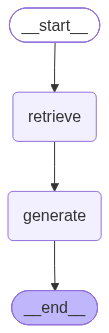

In [116]:
from IPython.display import Image, display

display(Image(rag_graph.get_graph().draw_mermaid_png()))